In [1]:
import pandas as pd # to load and manipulate data and for One-Hot Encoding
import numpy as np # to calculate the mean and standard deviation
import matplotlib.pyplot as plt # to draw graphs
from sklearn.tree import DecisionTreeClassifier # to build a classification tree
from sklearn.tree import plot_tree # to draw a classification tree
from sklearn.model_selection import train_test_split # to split data into training and testing sets
from sklearn.model_selection import cross_val_score # for cross validation
from sklearn.metrics import ConfusionMatrixDisplay # creates and draws a confusion matrix
# from sklearn.metrics import plot_confusion_matrix # to draw a confusion matrix

In [2]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data"

# Load the dataset, specifying that '?' denotes missing values
df = pd.read_csv(url, header=None)

## print the first 5 rows
df.head()

,0,1,2,3,4,5,6,7,8,9,10,11,12,13
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [3]:
## change the column numbers to column names
df.columns = ['age', 
              'sex', 
              'cp', 
              'restbp', 
              'chol', 
              'fbs', 
              'restecg', 
              'thalach', 
              'exang', 
              'oldpeak', 
              'slope', 
              'ca', 
              'thal', 
              'hd']
## print the first 5 rows (including the column names)
df.head()

,age,sex,cp,restbp,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,hd
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [4]:
df.dtypes

age        float64
sex        float64
cp         float64
restbp     float64
chol       float64
fbs        float64
restecg    float64
thalach    float64
exang      float64
oldpeak    float64
slope      float64
ca             str
thal           str
hd           int64
dtype: object

In [5]:
## print out unique values in the column called 'ca'
df['ca'].unique()

<StringArray>
['0.0', '3.0', '2.0', '1.0', '?']
Length: 5, dtype: str

In [6]:
## print out unique values in the column called 'thal'
df['thal'].unique()

<StringArray>
['6.0', '3.0', '7.0', '?']
Length: 4, dtype: str

In [11]:
missing_rows = df[pd.isna(df['ca']) | pd.isna(df['thal'])| # This is to check detects actual missing values such as NaN, None, or pd.NA
                   (df['ca'] == '?') | (df['thal'] == '?')]

# Check how many such rows exist
print(len(missing_rows))

6


In [12]:
## print out the rows that contain missing values.
df.loc[pd.isna(df['ca']) | pd.isna(df['thal'])|
       (df['ca'] == '?') | (df['thal'] == '?')]

,age,sex,cp,restbp,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,hd
87,53.0,0.0,3.0,128.0,216.0,0.0,2.0,115.0,0.0,0.0,1.0,0.0,?,0
166,52.0,1.0,3.0,138.0,223.0,0.0,0.0,169.0,0.0,0.0,1.0,?,3.0,0
192,43.0,1.0,4.0,132.0,247.0,1.0,2.0,143.0,1.0,0.1,2.0,?,7.0,1
266,52.0,1.0,4.0,128.0,204.0,1.0,0.0,156.0,1.0,1.0,2.0,0.0,?,2
287,58.0,1.0,2.0,125.0,220.0,0.0,0.0,144.0,0.0,0.4,2.0,?,7.0,0
302,38.0,1.0,3.0,138.0,175.0,0.0,0.0,173.0,0.0,0.0,1.0,?,3.0,0


In [13]:
len(df)

303

In [14]:

## save a new dataframe called "df_no_missing"
df_no_missing = df.loc[
    df['ca'].notna() & df['thal'].notna() &
    (df['ca'] != '?') & (df['thal'] != '?')
]

# Check how many rows are in the new dataframe, which should be len(df) - len(missing_rows)
len(df_no_missing)

297

In [15]:
## Make a new copy of the columns used to make predictions
X = df_no_missing.drop('hd', axis=1).copy() # alternatively: X = df_no_missing.iloc[:,:-1]
X.head()

,age,sex,cp,restbp,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0


In [16]:
## Make a new copy of the column of data we want to predict
y = df_no_missing['hd'].copy()
y.head()

0    0
1    2
2    1
3    0
4    0
Name: hd, dtype: int64

In [17]:
X["thal"] = pd.to_numeric(X["thal"]) 
X["ca"] = pd.to_numeric(X["ca"]) 

# One can add the option errors='coerce' here as well,
# but it is not necessary since we have already removed the rows with missing values.

# Now the final check to see if the data types have been changed to numeric
X.dtypes

age        float64
sex        float64
cp         float64
restbp     float64
chol       float64
fbs        float64
restecg    float64
thalach    float64
exang      float64
oldpeak    float64
slope      float64
ca         float64
thal       float64
dtype: object

In [18]:
X['cp'].unique()

array([1., 4., 3., 2.])

In [19]:
pd.get_dummies(X, columns=['cp']).head()

,age,sex,restbp,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,cp_1.0,cp_2.0,cp_3.0,cp_4.0
0,63.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,True,False,False,False
1,67.0,1.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,False,False,False,True
2,67.0,1.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,False,False,False,True
3,37.0,1.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,False,False,True,False
4,41.0,0.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,False,True,False,False


In [20]:
X_encoded = pd.get_dummies(X, columns=['cp', 
                                       'restecg', 
                                       'slope', 
                                       'thal'])
X_encoded.head()

,age,sex,restbp,chol,fbs,thalach,exang,oldpeak,ca,cp_1.0,...,cp_4.0,restecg_0.0,restecg_1.0,restecg_2.0,slope_1.0,slope_2.0,slope_3.0,thal_3.0,thal_6.0,thal_7.0
0,63.0,1.0,145.0,233.0,1.0,150.0,0.0,2.3,0.0,True,...,False,False,False,True,False,False,True,False,True,False
1,67.0,1.0,160.0,286.0,0.0,108.0,1.0,1.5,3.0,False,...,True,False,False,True,False,True,False,True,False,False
2,67.0,1.0,120.0,229.0,0.0,129.0,1.0,2.6,2.0,False,...,True,False,False,True,False,True,False,False,False,True
3,37.0,1.0,130.0,250.0,0.0,187.0,0.0,3.5,0.0,False,...,False,True,False,False,False,False,True,True,False,False
4,41.0,0.0,130.0,204.0,0.0,172.0,0.0,1.4,0.0,False,...,False,False,False,True,True,False,False,True,False,False


In [21]:
y.unique()

array([0, 2, 1, 3, 4])

In [22]:
y_not_zero_index = y > 0 # get the index for each non-zero value in y
y[y_not_zero_index] = 1  # set each non-zero value in y to 1
y.unique()               # verify that y only contains 0 and 1.

array([0, 1])

In [23]:
## split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, random_state=42)

## create a decisiont tree and fit it to the training data
clf_dt = DecisionTreeClassifier(
    max_depth=3,
    criterion="gini",
    random_state=42,
)

clf_dt = clf_dt.fit(X_train, y_train)

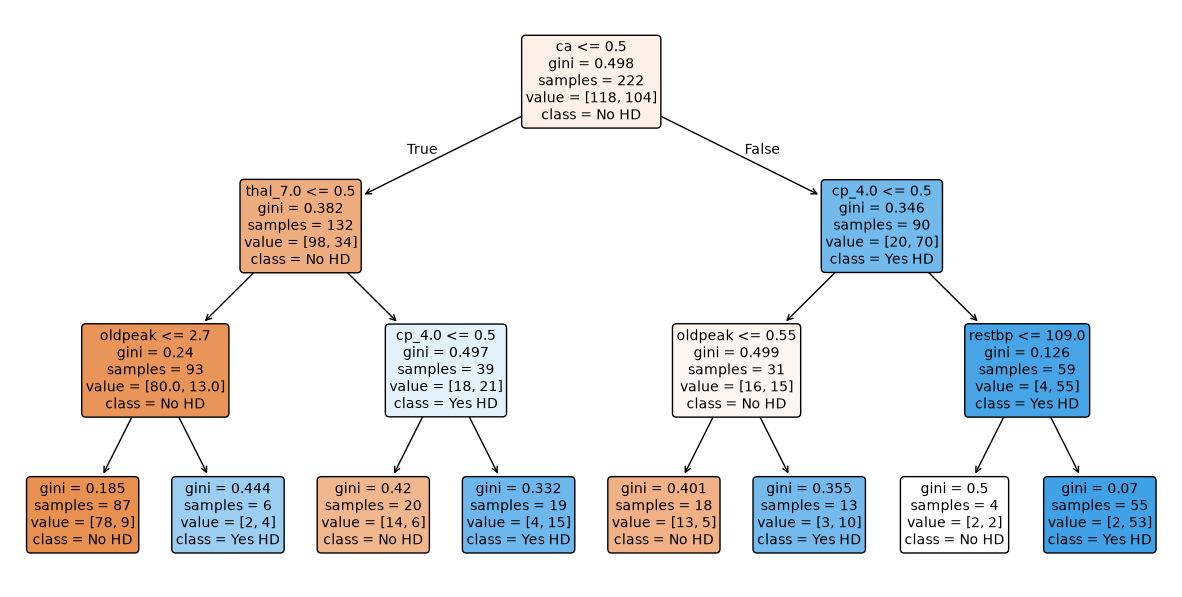

In [24]:
plt.figure(figsize=(15, 7.5))
plot_tree(clf_dt, 
          filled=True, 
          rounded=True, 
          class_names=["No HD", "Yes HD"], 
          feature_names=X_encoded.columns); 

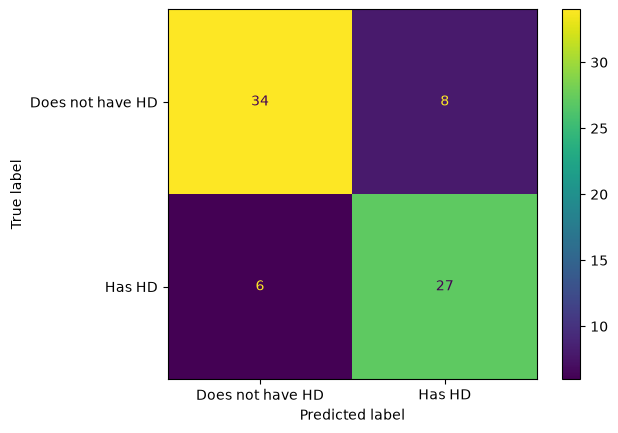

In [25]:
## plot_confusion_matrix() will run the test data down the tree and draw
## a confusion matrix.
ConfusionMatrixDisplay.from_estimator(clf_dt, 
                                      X_test, 
                                      y_test, 
                                      display_labels=["Does not have HD", "Has HD"])

In [27]:
# Function for computing accuracy, precision, recall, and F1 score
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

def compute_metrics(y_true, y_pred):
    """Helper function to compute accuracy, precision, recall, and F1 score at once."""
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred)
    recall = recall_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)

    # Pretty print the metrics
    print(f"Accuracy: {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1 Score: {f1:.4f}")

In [28]:
# Testing model on training sets
y_train_pred = clf_dt.predict(X_train)

# Compute metrics for training sets
print("Training Set Metrics:")
compute_metrics(y_train, y_train_pred)


Training Set Metrics:
Accuracy: 0.8514
Precision: 0.8817
Recall: 0.7885
F1 Score: 0.8325


In [29]:
# Testing model on test sets
y_test_pred = clf_dt.predict(X_test)

# Compute metrics for test sets
print("Test Set Metrics:")
compute_metrics(y_test, y_test_pred)

Test Set Metrics:
Accuracy: 0.8133
Precision: 0.7714
Recall: 0.8182
F1 Score: 0.7941


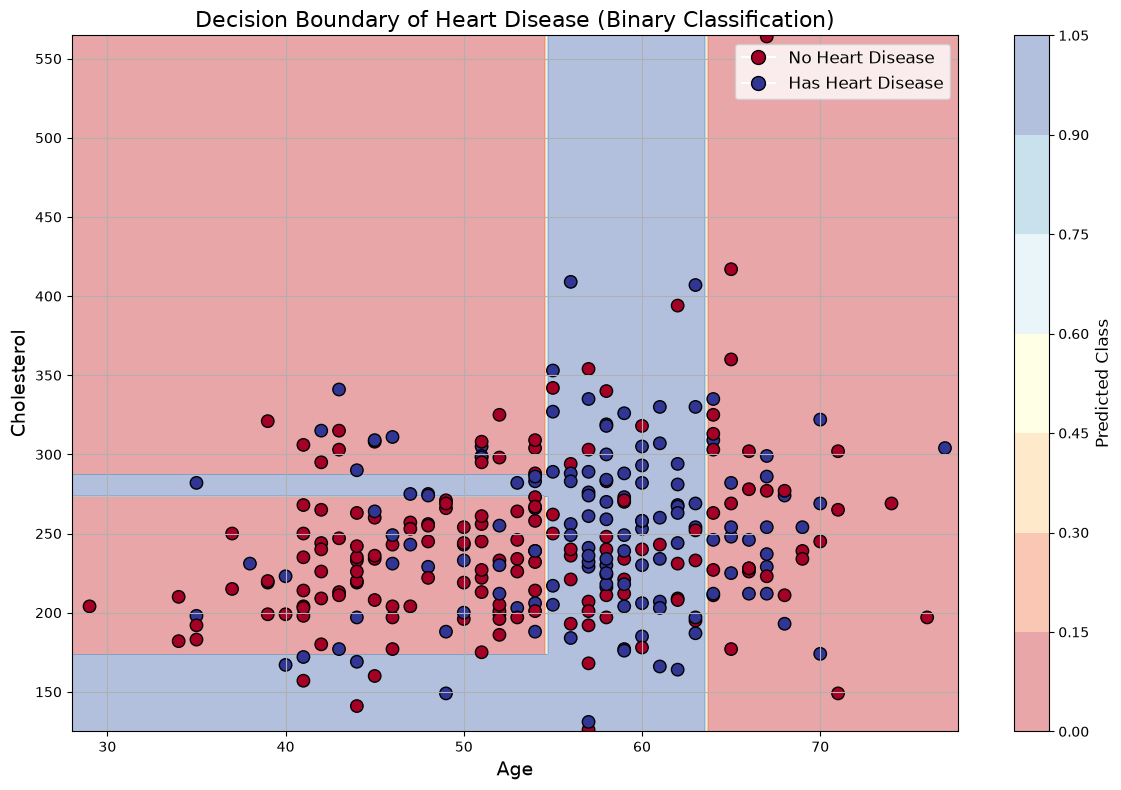

In [30]:
# Select 2 features and binarized target to see decision boundary
feature_names = ['age', 'chol']
X_vis = df_no_missing[feature_names].values

y = df_no_missing['hd'].copy()
y[y > 0] = 1
y = y.values

# Fit a decision tree for two features
clf_vis = DecisionTreeClassifier(max_depth=3,
    criterion="gini",
    random_state=42,)
clf_vis.fit(X_vis, y)

# Prepare the meshgrid for decision boundary
x_min, x_max = X_vis[:, 0].min() - 1, X_vis[:, 0].max() + 1
y_min, y_max = X_vis[:, 1].min() - 1, X_vis[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.25),
                     np.arange(y_min, y_max, 0.25))
Z = clf_vis.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)


# Plotting
fig, ax = plt.subplots(figsize=(12, 8))

# Plot decision boundary
contour = ax.contourf(xx, yy, Z, alpha=0.4, cmap=plt.cm.RdYlBu)

# Plot original data points
scatter = ax.scatter(X_vis[:, 0], X_vis[:, 1], c=y, cmap=plt.cm.RdYlBu, edgecolor='k', s=80)

# Axis labeling
ax.set_xlabel('Age', fontsize=14)
ax.set_ylabel('Cholesterol', fontsize=14)
ax.set_title("Decision Boundary of Heart Disease (Binary Classification)", fontsize=16)
ax.grid(True)

# Colorbar and legend
cbar = fig.colorbar(contour, ax=ax)
cbar.set_label("Predicted Class", fontsize=12)
legend_labels = ['No Heart Disease', 'Has Heart Disease']
legend_handles = [plt.Line2D([], [], marker='o', color='w', markerfacecolor=plt.cm.RdYlBu(0.), label=legend_labels[0], markersize=10, markeredgecolor='k'),
                  plt.Line2D([], [], marker='o', color='w', markerfacecolor=plt.cm.RdYlBu(1.), label=legend_labels[1], markersize=10, markeredgecolor='k')]
ax.legend(handles=legend_handles, fontsize=12, loc='upper right')

plt.tight_layout()
plt.show()

